# 04 — Ablación de momentum condicionada por estado

> Esta notebook pregunta si dos ajustes constantes, uno para el estado cash y otro para el estado long de TSMOM, capturan parte de la contribución observada en la LSTM. El control se propuso después de examinar 2024–2026: todo resultado de ese periodo es exploratorio y posterior al análisis de resultados, no evidencia confirmatoria.

## <b>Block 01 — Datos, baseline y cronología</b>

> Se reproducen sin cambios las convenciones de la notebook 03: XLE Gold local, momentum logarítmico 126d, EWMA $\lambda=0.94$, objetivo anual 12%, exposición máxima 1 y retorno de la sesión posterior a la decisión.

In [1]:
from pathlib import Path
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import torch
from torch import nn
torch.set_num_threads(1)

SEED, EPOCHS, LEARNING_RATE = 42, 80, 0.01
START = pd.Timestamp('2018-01-02')
MOMENTUM_FEATURES, LOOKBACK = (21, 63, 126), 63
EWMA_LAMBDA, EWMA_WARMUP = 0.94, 20
TARGET_VOLATILITY, MAX_EXPOSURE = 0.12, 1.00
ADJUSTMENT_LIMIT, RESEARCH_COST_PER_TURNOVER = 0.20, 0.0005
CYCLES = [('2024', pd.Timestamp('2023-12-31'), pd.Timestamp('2024-01-01'), pd.Timestamp('2024-12-31')), ('2025', pd.Timestamp('2024-12-31'), pd.Timestamp('2025-01-01'), pd.Timestamp('2025-12-31')), ('2026', pd.Timestamp('2025-12-31'), pd.Timestamp('2026-01-01'), None)]

def find_repo_root(start=Path.cwd()):
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / 'Momentum_systematic_strategies').is_dir(): return candidate
    raise FileNotFoundError('No se encontró la raíz del repositorio.')

ROOT = find_repo_root()
GOLD_PATH = ROOT / 'Momentum_systematic_strategies' / 'data' / 'gold' / 'daily_series' / 'etf' / 'XLE.parquet'
gold = pl.read_parquet(GOLD_PATH).select('session_date', 'adjusted_close').sort('session_date')
GOLD_END = pd.Timestamp(gold.get_column('session_date').max())
frame = pd.DataFrame(gold.filter(pl.col('session_date') >= START.date()).to_dict(as_series=False)).rename(columns={'session_date': 'decision_date'})
frame['decision_date'] = pd.to_datetime(frame['decision_date']); frame['ret_1d'] = frame['adjusted_close'].pct_change()
for horizon in MOMENTUM_FEATURES: frame['mom_{}'.format(horizon)] = np.log(frame['adjusted_close'] / frame['adjusted_close'].shift(horizon))
ret = frame['ret_1d'].to_numpy(float); variance = np.full(len(frame), np.nan)
first_valid = np.flatnonzero(np.isfinite(ret))[0]; initial_index = first_valid + EWMA_WARMUP - 1
variance[initial_index] = np.mean(ret[first_valid:initial_index + 1] ** 2)
for i in range(initial_index + 1, len(frame)): variance[i] = EWMA_LAMBDA * variance[i - 1] + (1 - EWMA_LAMBDA) * ret[i] ** 2
frame['ewma_vol_annual'] = np.sqrt(variance) * math.sqrt(252)
frame['baseline_position'] = np.where(frame['mom_126'] > 0, np.minimum(MAX_EXPOSURE, TARGET_VOLATILITY / frame['ewma_vol_annual']), 0.0)
frame['return_date'], frame['next_return'] = frame['decision_date'].shift(-1), frame['ret_1d'].shift(-1)
feature_columns = ['ret_1d', 'mom_21', 'mom_63', 'mom_126', 'ewma_vol_annual']
frame['ready'] = frame[feature_columns].notna().all(axis=1).astype(int).rolling(LOOKBACK).sum().eq(LOOKBACK); frame['_row'] = np.arange(len(frame))
sample = frame.loc[frame['ready'] & frame['next_return'].notna()].copy().reset_index(drop=True)
assert (sample['return_date'] > sample['decision_date']).all() and sample['baseline_position'].between(0, 1).all()
print('Gold hasta {} | muestra causal: {} → {}'.format(GOLD_END.date(), sample.decision_date.min().date(), sample.return_date.max().date()))

Gold hasta 2026-11-17 | muestra causal: 2018-10-01 → 2026-11-17


## <b>Block 02 — Corrector de dos estados</b>

> La política aprende solo $\alpha_{cash}$ y $\alpha_{long}$, ambos acotados a $[-0.20, 0.20]$: $w_t=clip(w_t^{base}+\alpha_{estado(t)},0,1)$. La inicialización es cero, por lo que reproduce exactamente TSMOM antes del entrenamiento.

In [2]:
class AnchoredLSTM(nn.Module):
    def __init__(self, n_features):
        super().__init__(); self.lstm = nn.LSTM(n_features, 8, num_layers=1, batch_first=True); self.residual = nn.Linear(8, 1)
        nn.init.zeros_(self.residual.weight); nn.init.zeros_(self.residual.bias)
    def forward(self, x):
        hidden, _ = self.lstm(x); return ADJUSTMENT_LIMIT * torch.tanh(self.residual(hidden[:, -1, :]).squeeze(-1))

class AnchoredFeedForward(nn.Module):
    def __init__(self, n_features):
        super().__init__(); self.hidden, self.residual = nn.Linear(n_features, 8), nn.Linear(8, 1)
        nn.init.zeros_(self.residual.weight); nn.init.zeros_(self.residual.bias)
    def forward(self, x): return ADJUSTMENT_LIMIT * torch.tanh(self.residual(torch.tanh(self.hidden(x))).squeeze(-1))

class ConstantCorrection(nn.Module):
    def __init__(self): super().__init__(); self.raw = nn.Parameter(torch.zeros(()))
    def forward(self, x): return ADJUSTMENT_LIMIT * torch.tanh(self.raw).expand(x.shape[0])

class StateConditionalCorrection(nn.Module):
    def __init__(self): super().__init__(); self.raw_cash, self.raw_long = nn.Parameter(torch.zeros(())), nn.Parameter(torch.zeros(()))
    def forward(self, baseline):
        alpha_cash, alpha_long = ADJUSTMENT_LIMIT * torch.tanh(self.raw_cash), ADJUSTMENT_LIMIT * torch.tanh(self.raw_long)
        return torch.where(baseline > 0, alpha_long, alpha_cash)
    def alphas(self): return (ADJUSTMENT_LIMIT * torch.tanh(self.raw_cash)).item(), (ADJUSTMENT_LIMIT * torch.tanh(self.raw_long)).item()

def train_model(model, inputs, train_idx, baseline_tensor, returns_tensor):
    optimizer, index = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE), torch.tensor(train_idx, dtype=torch.long)
    for _ in range(EPOCHS):
        optimizer.zero_grad(); position = torch.clamp(baseline_tensor[index] + model(inputs[index]), 0.0, 1.0)
        turnover = torch.cat(((position[1:2] - position[:1]).abs(), (position[2:] - position[1:-1]).abs()))
        net = position[1:] * returns_tensor[index][1:] - RESEARCH_COST_PER_TURNOVER * turnover
        loss = -(net.mean() / net.std(unbiased=False).clamp_min(1e-6) * math.sqrt(252)); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); optimizer.step()
    return model

parameter_table = pd.DataFrame({'estrategia': ['TSMOM', 'Constante', 'Estado condicional', 'Feedforward', 'LSTM'], 'parámetros entrenables': [0, 1, 2, 57, 489]})
parameter_table

,estrategia,parámetros entrenables
0,TSMOM,0
1,Constante,1
2,Estado condicional,2
3,Feedforward,57
4,LSTM,489


## <b>Block 03 — Walk-forward con continuidad económica</b>

> Cada modelo se reentrena con historia expansiva hasta el cierre del último retorno permitido. Antes de la primera decisión del ciclo nuevo se mantiene la posición heredada y se registra su P&L sin coste; el rebalanceo posterior cobra turnover contra ese peso realmente mantenido.

In [3]:
legacy_labels = ['TSMOM baseline', 'Corrección constante', 'Feedforward actual', 'LSTM 63 sesiones']
labels = legacy_labels + ['Estado condicional']
daily_parts, schedule_rows, alpha_rows = [], [], []
previous_position = {label: 0.0 for label in labels}

for cycle, train_end, evaluation_start, evaluation_end in CYCLES:
    evaluation_end = GOLD_END if evaluation_end is None else min(evaluation_end, GOLD_END)
    train_idx = np.flatnonzero((sample['return_date'] <= train_end).to_numpy())
    available_date = sample.loc[train_idx, 'return_date'].max()
    target_idx = np.flatnonzero(((sample['return_date'] >= evaluation_start) & (sample['return_date'] <= evaluation_end)).to_numpy())
    active_idx = target_idx[sample.loc[target_idx, 'decision_date'].to_numpy() > available_date]
    bridge_idx = target_idx[sample.loc[target_idx, 'decision_date'].to_numpy() <= available_date]
    assert len(target_idx) == len(active_idx) + len(bridge_idx) and sample.loc[active_idx, 'decision_date'].min() > available_date

    train_rows, raw = sample.loc[train_idx, '_row'].to_numpy(), frame[feature_columns].to_numpy(dtype=np.float32)
    mean, std = raw[train_rows].mean(0), np.maximum(raw[train_rows].std(0), 1e-8); scaled = (raw - mean) / std
    rows = sample['_row'].to_numpy(); sequence = np.stack([scaled[row - LOOKBACK + 1:row + 1] for row in rows]).astype(np.float32); current = scaled[rows].astype(np.float32)
    assert np.array_equal(sequence[:, -1, :], current)
    seq_t, cur_t = torch.tensor(sequence), torch.tensor(current)
    base_t, ret_t = torch.tensor(sample['baseline_position'].to_numpy(dtype=np.float32)), torch.tensor(sample['next_return'].to_numpy(dtype=np.float32))

    # El orden preserva exactamente la reproducción de las cuatro políticas de la notebook 03.
    np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED)
    lstm = train_model(AnchoredLSTM(5), seq_t, train_idx, base_t, ret_t)
    feedforward = train_model(AnchoredFeedForward(5), cur_t, train_idx, base_t, ret_t)
    constant = train_model(ConstantCorrection(), cur_t, train_idx, base_t, ret_t)
    state = train_model(StateConditionalCorrection(), base_t, train_idx, base_t, ret_t)
    with torch.no_grad():
        assert np.array_equal(StateConditionalCorrection()(base_t).numpy(), np.zeros(len(sample), dtype=np.float32))
        cash_alpha, long_alpha = state.alphas()
        all_positions = {
            'TSMOM baseline': sample['baseline_position'].to_numpy(),
            'Corrección constante': np.clip(sample['baseline_position'].to_numpy() + constant(cur_t).numpy(), 0, 1),
            'Feedforward actual': np.clip(sample['baseline_position'].to_numpy() + feedforward(cur_t).numpy(), 0, 1),
            'LSTM 63 sesiones': np.clip(sample['baseline_position'].to_numpy() + lstm(seq_t).numpy(), 0, 1),
            'Estado condicional': np.clip(sample['baseline_position'].to_numpy() + state(base_t).numpy(), 0, 1),
        }
    alpha_rows.append({'ciclo': cycle, 'alpha_cash (%)': cash_alpha * 100, 'alpha_long (%)': long_alpha * 100})
    bridge_dates, bridge_returns = sample.loc[bridge_idx, 'return_date'].to_numpy(), sample.loc[bridge_idx, 'next_return'].to_numpy()
    active_dates, active_returns = sample.loc[active_idx, 'return_date'].to_numpy(), sample.loc[active_idx, 'next_return'].to_numpy()
    for label, position in all_positions.items():
        if len(bridge_idx):
            held = np.full(len(bridge_idx), previous_position[label])
            daily_parts.append(pd.DataFrame({'cycle': cycle, 'return_date': bridge_dates, 'estrategia': label, 'position': held, 'gross': held * bridge_returns, 'costs': 0.0, 'net': held * bridge_returns, 'turnover': 0.0, 'origen': 'posición arrastrada'}))
        weights = position[active_idx]; turnover = np.r_[abs(weights[0] - previous_position[label]), abs(np.diff(weights))]
        costs = RESEARCH_COST_PER_TURNOVER * turnover
        daily_parts.append(pd.DataFrame({'cycle': cycle, 'return_date': active_dates, 'estrategia': label, 'position': weights, 'gross': weights * active_returns, 'costs': costs, 'net': weights * active_returns - costs, 'turnover': turnover, 'origen': 'modelo nuevo'}))
        previous_position[label] = weights[-1]
    schedule_rows.append({'ciclo': cycle, 'modelo disponible tras': available_date.date(), 'primera decisión': sample.loc[active_idx, 'decision_date'].min().date(), 'primer retorno del modelo': pd.Timestamp(active_dates[0]).date(), 'sesiones arrastradas': len(bridge_idx), 'retornos': len(target_idx)})

daily = pd.concat(daily_parts, ignore_index=True).sort_values(['estrategia', 'return_date']).reset_index(drop=True)
schedule, alphas = pd.DataFrame(schedule_rows), pd.DataFrame(alpha_rows)
expected_dates = pd.DatetimeIndex(frame.loc[(frame['decision_date'] >= pd.Timestamp('2024-01-01')) & (frame['decision_date'] <= GOLD_END), 'decision_date'])
assert daily.groupby('estrategia')['return_date'].apply(tuple).nunique() == 1
assert pd.DatetimeIndex(daily.loc[daily['estrategia'] == 'TSMOM baseline', 'return_date']).equals(expected_dates)
display(schedule); display(alphas.round(3))

,ciclo,modelo disponible tras,primera decisión,primer retorno del modelo,sesiones arrastradas,retornos
0,2024,2023-12-29,2024-01-02,2024-01-03,1,252
1,2025,2024-12-31,2025-01-02,2025-01-03,1,250
2,2026,2025-12-31,2026-01-02,2026-01-05,1,221


,ciclo,alpha_cash (%),alpha_long (%)
0,2024,11.784,11.180
1,2025,12.222,11.364
2,2026,12.291,11.228


## <b>Block 04 — Comparación económica y atribución por estado</b>

> Las cinco políticas comparten cada sesión Gold de 2024–2026. Primero se verifica la reproducción de las cuatro estrategias congeladas; después se describe el control de dos estados sin usar sus resultados para modificar el diseño.

,estrategia,retorno neto compuesto (%),volatilidad anual (%),Sharpe neto,max drawdown (%),exposición media (%),turnover total,costes totales (%),Δ neto diario vs TSMOM (bps),Δ neto diario vs LSTM (bps)
0,Corrección constante,8.416,13.316,0.278,-22.365,56.637,33.712,1.686,0.959,0.112
1,Estado condicional,8.351,13.207,0.278,-22.200,56.260,33.463,1.673,0.945,0.098
2,Feedforward actual,1.981,8.697,0.122,-17.579,34.986,34.159,1.708,-0.091,-0.937
3,LSTM 63 sesiones,8.982,9.224,0.371,-15.270,37.351,46.032,2.302,0.846,0.000
4,TSMOM baseline,1.945,11.115,0.116,-22.057,44.858,33.875,1.694,0.000,-0.846


,cycle,estado baseline en t,sesiones,Δ exposición media (pp),Δ bruto suma (%),Δ costes suma (%),Δ neto suma (%)
0,2024,cash,91,11.655,2.995,-0.002,2.997
1,2024,long,161,10.989,-1.945,-0.009,-1.935
2,2025,cash,107,12.218,1.928,-0.004,1.932
3,2025,long,143,11.364,-0.591,-0.005,-0.587
4,2026,long,221,11.229,4.422,0.000,4.422


Reproducción de las cuatro políticas de la notebook 03: sí. Identidad de atribución por estado: sí.


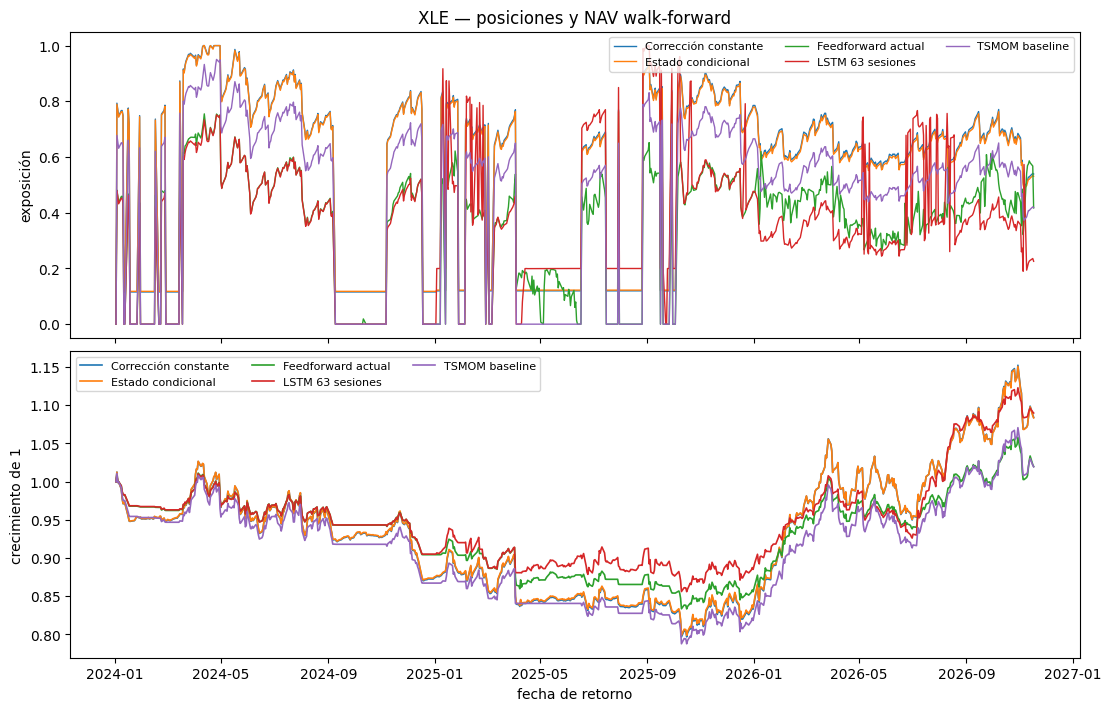

In [4]:
def metrics_for(part):
    net = part['net'].to_numpy(); nav = np.r_[1.0, np.cumprod(1 + net)]; std = net.std(ddof=0)
    return pd.Series({'retorno neto compuesto (%)': (nav[-1] - 1) * 100, 'volatilidad anual (%)': std * math.sqrt(252) * 100, 'Sharpe neto': net.mean() / max(std, 1e-8) * math.sqrt(252), 'max drawdown (%)': (nav / np.maximum.accumulate(nav) - 1).min() * 100, 'exposición media (%)': part['position'].mean() * 100, 'turnover total': part['turnover'].sum(), 'costes totales (%)': part['costs'].sum() * 100})

combined = daily.groupby('estrategia', sort=False).apply(metrics_for, include_groups=False).reset_index()
reference_03 = {'TSMOM baseline': [1.945, 11.115, 0.116, -22.057, 44.858, 33.875, 1.694], 'Corrección constante': [8.416, 13.316, 0.278, -22.365, 56.637, 33.712, 1.686], 'Feedforward actual': [1.981, 8.697, 0.122, -17.579, 34.986, 34.159, 1.708], 'LSTM 63 sesiones': [8.982, 9.224, 0.371, -15.270, 37.351, 46.032, 2.302]}
metric_columns = list(combined.columns[1:])
for label, values in reference_03.items(): assert np.allclose(combined.set_index('estrategia').loc[label, metric_columns].to_numpy(float), values, atol=0.006)

baseline_net = daily.loc[daily['estrategia'] == 'TSMOM baseline', ['return_date', 'net']].set_index('return_date')['net']
lstm_net = daily.loc[daily['estrategia'] == 'LSTM 63 sesiones', ['return_date', 'net']].set_index('return_date')['net']
daily_compare = daily.join(baseline_net.rename('baseline_net'), on='return_date').join(lstm_net.rename('lstm_net'), on='return_date')
delta = daily_compare.groupby('estrategia', sort=False).apply(lambda x: pd.Series({'Δ neto diario vs TSMOM (bps)': (x['net'] - x['baseline_net']).mean() * 1e4, 'Δ neto diario vs LSTM (bps)': (x['net'] - x['lstm_net']).mean() * 1e4}), include_groups=False).reset_index()
combined = combined.merge(delta, on='estrategia')

base = daily.loc[daily['estrategia'] == 'TSMOM baseline', ['return_date', 'position', 'gross', 'costs', 'net']].rename(columns={'position': 'baseline_position', 'gross': 'baseline_gross', 'costs': 'baseline_costs', 'net': 'baseline_net'})
state_attr = daily.loc[daily['estrategia'] == 'Estado condicional'].merge(base, on='return_date', validate='one_to_one')
state_attr['estado baseline en t'] = np.where(state_attr['baseline_position'] > 0, 'long', 'cash')
state_attr['Δ exposición (pp)'] = (state_attr['position'] - state_attr['baseline_position']) * 100
state_attr['Δ bruto (%)'] = (state_attr['gross'] - state_attr['baseline_gross']) * 100
state_attr['Δ costes (%)'] = (state_attr['costs'] - state_attr['baseline_costs']) * 100
state_attr['Δ neto (%)'] = (state_attr['net'] - state_attr['baseline_net']) * 100
assert np.allclose(state_attr['Δ neto (%)'], state_attr['Δ bruto (%)'] - state_attr['Δ costes (%)'])
state_by_condition = state_attr.groupby(['cycle', 'estado baseline en t'], sort=False).agg(sesiones=('return_date', 'size'), **{'Δ exposición media (pp)': ('Δ exposición (pp)', 'mean'), 'Δ bruto suma (%)': ('Δ bruto (%)', 'sum'), 'Δ costes suma (%)': ('Δ costes (%)', 'sum'), 'Δ neto suma (%)': ('Δ neto (%)', 'sum')}).reset_index()

display(combined.round(3)); display(state_by_condition.round(3))
print('Reproducción de las cuatro políticas de la notebook 03: sí. Identidad de atribución por estado: sí.')

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, layout='constrained')
for label, part in daily.groupby('estrategia', sort=False):
    part = part.sort_values('return_date'); axes[0].plot(part['return_date'], part['position'], lw=1.0, label=label); axes[1].plot(part['return_date'], np.cumprod(1 + part['net'].to_numpy()), lw=1.2, label=label)
axes[0].set_title('XLE — posiciones y NAV walk-forward'); axes[0].set_ylabel('exposición'); axes[0].set_ylim(-0.05, 1.05); axes[0].legend(ncol=3, fontsize=8)
axes[1].set_ylabel('crecimiento de 1'); axes[1].set_xlabel('fecha de retorno'); axes[1].legend(ncol=3, fontsize=8)
plt.show()

## <b>Conclusión</b>

- La política de estado añade solo dos parámetros y conserva la misma información y contabilidad que las políticas anteriores.
- Su comparación con LSTM indica cuánto puede explicarse mediante una regla dependiente únicamente del estado long/cash, pero no identifica una causa única de cualquier diferencia.
- Este control se diseñó después de revisar 2024–2026; sus resultados son exploratorios y posteriores al análisis, incluso si resultan favorables.
- No representa ejecución con órdenes o fills, y no establece evidencia confirmatoria de alpha ni una estrategia seleccionada.